# 0. Packages

In [1]:
%load_ext autoreload
%autoreload 2

In [34]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 1. Калибруем модель процентных ставок (RUB)

В исходной постановке модель CIR выглядит следующим образом:

$$
dr_t = a(b-r_t)dt + \sqrt{r_t}\sigma dW_t
$$

Далее для оценки предлагается перейти от непрерывной дифференциальной формы к дискретному разностному уровнению и записать его в виде (здесь $\varepsilon_i \sim N(0, 1)$). Да, это будет приблеженное выражение, но есть что есть:

$$
\Delta{r_i} \approx a(b-r_{i-1})\Delta{t_i} + \sigma \sqrt{r_{i-1} \Delta{t_i}}\varepsilon_i
$$

$$
r_i - r_{i-1} \approx a(b-r_{i-1})\Delta{t_i} + \sigma \sqrt{r_{i-1} \Delta{t_i}}\varepsilon_i
$$

(Делим на $\sqrt{r_{i-1} \Delta{t_i}}$ в предположении, что $r_{i-1} > 0$)

$$
\frac{r_i - r_{i-1}}{\sqrt{r_{i-1} \Delta{t_i}}} \approx \frac{a(b-r_{i-1})\sqrt{\Delta{t_i}}}{\sqrt{r_{i-1}}} + \sigma \varepsilon_i
$$

(и это уже можно представить в виде)

$$
\frac{r_i - r_{i-1}}{\sqrt{r_{i-1} \Delta{t_i}}} \approx ab\sqrt{\frac{\Delta{t_i}}{r_{i-1}}}-a\sqrt{r_{i-1}\Delta{t_i}} + \sigma \varepsilon_i
$$

Теперь мы можем оценить через МНК и получить оценки $a$, $b$ и $\sigma$. Заметим, что в такой поставноке мы идентифицируем только $ab$ и $a$, поэтому $\hat{b}=\frac{\hat{{ab}}}{\hat{a}}$

И еще важно упомянуть, что мы будем рассматривать такой калибровочный период:
- Начало: 2020-04-01
- Конец: 2021-12-08

В блокноте [00_data_collection.ipynb](../notebooks/00_data_collection.ipynb) на графиках видно, что после первого квартрала (примерно) 2020 года у EFFR как будто сменился режим, поэтому для однородности и, не в последнюю очередь, стабильности калибровки берем этот период. А ограничиваем себя сверху 2021-12-08 потому, что в методологии ЦБ РФ написано, что RUONIA публикуется за следующий рабочий день не позднее 15-00 мск

In [3]:
ruonia = (
    pd.read_csv("../data/prepared/ruonia.csv")
    .query("(dt >= '2020-04-01') & (dt <= '2021-12-08')")
)
ruonia['dt'] = pd.to_datetime(ruonia['dt'])
ruonia = ruonia.sort_values(by="dt", ascending=False)

ruonia['r_i'] = ruonia['ruonia']
ruonia['r_{i-1}'] = ruonia['ruonia'].shift(-1)
ruonia['Delta{t}'] = (ruonia['dt'] - ruonia['dt'].shift(-1)).dt.total_seconds() / (365 * 24 * 60 * 60)

ruonia['y'] = (ruonia['r_i'] - ruonia['r_{i-1}']) / np.sqrt(ruonia['r_{i-1}'] * ruonia['Delta{t}'])
ruonia['x1'] = np.sqrt(ruonia['Delta{t}'] / ruonia['r_{i-1}'])
ruonia['x2'] = -np.sqrt(ruonia['r_{i-1}'] * ruonia['Delta{t}'])

ruonia = ruonia.dropna()

print(ruonia.shape)

ruonia.head()

(415, 8)


,dt,ruonia,r_i,r_{i-1},Delta{t},y,x1,x2
15,2021-12-08,0.0744,0.0744,0.0724,0.002740,0.142006,0.194529,-0.014084
16,2021-12-07,0.0724,0.0724,0.0721,0.002740,0.021345,0.194933,-0.014055
17,2021-12-06,0.0721,0.0721,0.0716,0.008219,0.020611,0.338811,-0.024259
18,2021-12-03,0.0716,0.0716,0.0693,0.002740,0.166920,0.198832,-0.013779
19,2021-12-02,0.0693,0.0693,0.0693,0.002740,0.000000,0.198832,-0.013779


In [4]:
model = sm.OLS(
    endog=ruonia['y'],
    exog=ruonia[['x1', 'x2']]
).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.002
Model:                            OLS   Adj. R-squared (uncentered):             -0.002
Method:                 Least Squares   F-statistic:                             0.4970
Date:                Sun, 22 Nov 2026   Prob (F-statistic):                       0.609
Time:                        21:23:56   Log-Likelihood:                          327.49
No. Observations:                 415   AIC:                                     -651.0
Df Residuals:                     413   BIC:                                     -642.9
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0825      0.095      0.872      0.384      -0.104       0.268
x2             1.4498      1.911      0.758      0.449      -2.308       5.207
==============================================================================
Omnibus:                      212.667   Durbin-Watson:                   2.073
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3440.598
Skew:                           1.778   Prob(JB):                         0.00
Kurtosis:                      16.650   Cond. No.                         102.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [5]:
a_hat = model.params["x2"]
b_hat = model.params["x1"] / a_hat
sigma_hat = np.sqrt(model.ssr / model.df_resid)

print(f"a = {a_hat:.6f}")
print(f"b = {b_hat:.6f}")
print(f"sigma = {sigma_hat:.6f}")

a = 1.449818
b = 0.056892
sigma = 0.110179


In [6]:
ruonia["residual"] = model.resid
ruonia["innovation"] = model.resid / sigma_hat

In [7]:
print(ruonia["innovation"].mean(), ruonia["innovation"].std())

0.021201866273288208 0.9985659398028371


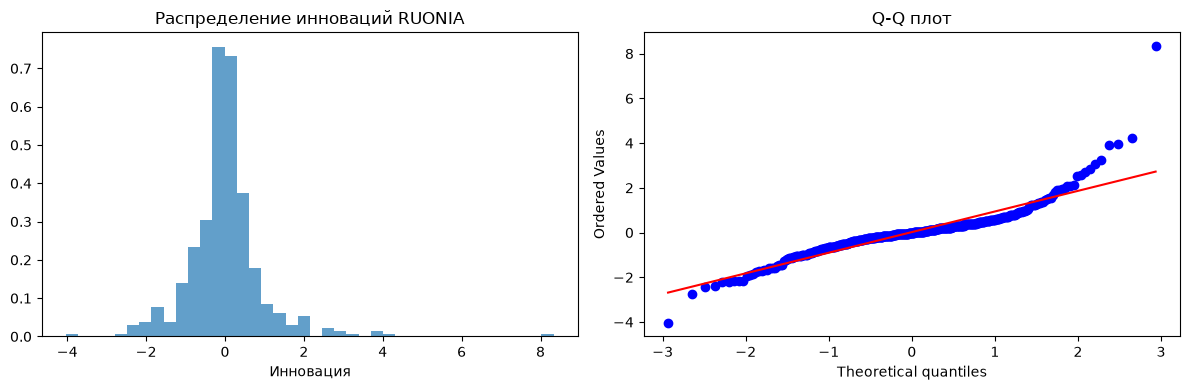

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(
    ruonia["innovation"],
    bins=40,
    density=True,
    alpha=0.7,
)
axes[0].set_title("Распределение инноваций RUONIA")
axes[0].set_xlabel("Инновация")

stats.probplot(
    ruonia["innovation"],
    dist="norm",
    plot=axes[1],
)
axes[1].set_title("Q-Q плот")
plt.tight_layout()
plt.show()

Под инновациями понимается по сути наша оценка $\varepsilon$. Далее ее (и не только) мы будем использовать, чтобы задать корреляционную матрицу для винеровских процессов. Пока лишь отметим, что с точки зрения эконометрики статистическое качество такой аппроксимации скорее удоволитворительное. Понятно, что одной лишь динамикой RUONIA ее же саму объяснить сложно, но в нашем случае требовалось получить какие-никакие оценки скорости возврата к среднему, уровень среднего и волатильность

# 2. Калибруем модель процентных ставок (USD)

Здесь точно такая же методология

In [9]:
effr = (
    pd.read_csv("../data/prepared/effr.csv")
    .query("(dt >= '2020-04-01') & (dt <= '2021-12-08')")
)
effr['dt'] = pd.to_datetime(effr['dt'])
effr = effr.sort_values(by="dt", ascending=False)

effr['r_i'] = effr['effr']
effr['r_{i-1}'] = effr['effr'].shift(-1)
effr['Delta{t}'] = (effr['dt'] - effr['dt'].shift(-1)).dt.total_seconds() / (365 * 24 * 60 * 60)

effr['y'] = (effr['r_i'] - effr['r_{i-1}']) / np.sqrt(effr['r_{i-1}'] * effr['Delta{t}'])
effr['x1'] = np.sqrt(effr['Delta{t}'] / effr['r_{i-1}'])
effr['x2'] = -np.sqrt(effr['r_{i-1}'] * effr['Delta{t}'])

effr = effr.dropna()

print(effr.shape)

effr.head()

(410, 8)


,dt,effr,r_i,r_{i-1},Delta{t},y,x1,x2
1286,2021-12-08,0.0008,0.0008,0.0008,0.002740,0.0,1.850583,-0.001480
1285,2021-12-07,0.0008,0.0008,0.0008,0.002740,0.0,1.850583,-0.001480
1284,2021-12-06,0.0008,0.0008,0.0008,0.008219,0.0,3.205304,-0.002564
1283,2021-12-03,0.0008,0.0008,0.0008,0.002740,0.0,1.850583,-0.001480
1282,2021-12-02,0.0008,0.0008,0.0008,0.002740,0.0,1.850583,-0.001480


In [10]:
model = sm.OLS(
    endog=effr['y'],
    exog=effr[['x1', 'x2']]
).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.021
Model:                            OLS   Adj. R-squared (uncentered):              0.016
Method:                 Least Squares   F-statistic:                              4.329
Date:                Sun, 22 Nov 2026   Prob (F-statistic):                      0.0138
Time:                        21:23:58   Log-Likelihood:                          827.73
No. Observations:                 410   AIC:                                     -1651.
Df Residuals:                     408   BIC:                                     -1643.
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0100      0.003      2.941      0.003       0.003       0.017
x2            12.5200      4.383      2.857      0.004       3.905      21.135
==============================================================================
Omnibus:                      255.551   Durbin-Watson:                   2.479
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            12715.236
Skew:                           1.937   Prob(JB):                         0.00
Kurtosis:                      30.006   Cond. No.                     6.15e+03
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 6.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [11]:
a_hat = model.params["x2"]
b_hat = model.params["x1"] / a_hat
sigma_hat = np.sqrt(model.ssr / model.df_resid)

print(f"a = {a_hat:.6f}")
print(f"b = {b_hat:.6f}")
print(f"sigma = {sigma_hat:.6f}")

a = 12.520048
b = 0.000796
sigma = 0.032214


In [12]:
effr["residual"] = model.resid
effr["innovation"] = model.resid / sigma_hat

In [13]:
print(effr['innovation'].mean(), effr['innovation'].std())

-0.011073785888735286 0.9987152164983141


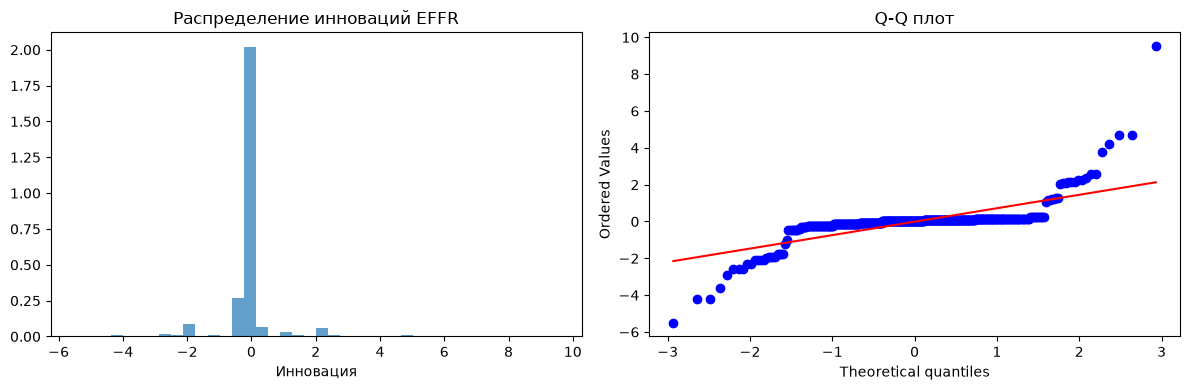

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(
    effr["innovation"],
    bins=40,
    density=True,
    alpha=0.7,
)
axes[0].set_title("Распределение инноваций EFFR")
axes[0].set_xlabel("Инновация")

stats.probplot(
    effr["innovation"],
    dist="norm",
    plot=axes[1],
)
axes[1].set_title("Q-Q плот")
plt.tight_layout()
plt.show()

В силу низкой вариативности на выбранном периоде, EFFR оценки могут быть чуть менее стабильными, чем у RUONIA, но тем не менее как первое приближение фиксируем их

# 4. Калибруем модель обменного курса

Пусть исходная модель валютного курса под физической мерой определяется следующей формулой:

$$
dS_t = (r_t^{RUB} - r_t^{USD} + \lambda)S_tdt + \sigma S_t dW_t
$$

Да, речь про физическую меру была и для калибровок моделей мнгновенных ставок. То есть текущий подход выстроен так, что мы разбираемся с параметрами моделей для физической меры, а затем как-то переходим к риск-нейтральной. Итак, по ТЗ требуется работать с логарифмической моделью обменного курса, поэтому ее для начала нужно получить. Поскольку мы недавно (на момент написания этого текста получается, что вчера) прошли формулу Ито, то здесь для закрепления мы чуть подробнее распишем вывод. Формула Ито утверждает, что если случайный процесс $S_t$ удоволетворяет:
$$
dS_t=\mu_t S_t dt + \sigma S_t dW_t
$$
а мы хотим получить дифференциал f(S_t)$,
то:
$$
df(S_t)=(f^{'}(S_t)\mu_t S_t+0.5 f^{''}(S_t){\sigma}^2 {S_t}^2)dt + f^{'}(S_t)\sigma S_t dW_t
$$

В нашем случае выходит после всех преобразований и сокращений:
$$
d\ln S_t = (\mu_t - 0.5 {\sigma}^2)dt + \sigma dW_t
$$

И если вспомнить, что $\mu = r_t^{RUB} - r_t^{USD} + \lambda$, то:
$$
d\ln S_t = (r_t^{RUB} - r_t^{USD} + \lambda - 0.5 {\sigma}^2)dt + \sigma dW_t
$$

Поскольку мы будем придерживаться схемы Эйлера, то также переходим от непрерывного случая к разностному уравнению. Приблизительно выходит, что:

$$
\ln S_i - \ln S_{i-1} \approx (r_{i-1}^{RUB} - r_{i-1}^{USD} + \lambda - 0.5 {\sigma}^2)\Delta{t_i} + \sigma \sqrt{\Delta{t_i}}\varepsilon_i
$$

$$
\ln\frac{S_i}{S_{i-1}} \approx (r_{i-1}^{RUB} - r_{i-1}^{USD} + \lambda - 0.5 {\sigma}^2)\Delta{t_i} + \sigma \sqrt{\Delta{t_i}}\varepsilon_i
$$

где $\varepsilon_i$ все также распределено $N(0, 1)$

Тогда мы можем оценить (по мнк с учетом идентификации) только такие параметры: $\lambda - 0.5 {\sigma}^2$ и $\sigma$

Поделим на $\sqrt{\Delta{t_i}}$ и спустя пару преобразований получим:

$$
\frac{\ln \frac{S_i}{S_{i-1}}}{\sqrt{\Delta{t_i}}} + \sqrt{\Delta{t_i}}(r_{i-1}^{USD} - r_{i-1}^{RUB})
\approx
(\lambda - 0.5 {\sigma}^2)\sqrt{\Delta{t_i}} + \sigma \varepsilon_i
$$

Период рассматриваем такой же, чтобы корреляция инноваций считалась на равных временных точках

In [15]:
fx = (
    pd.read_csv("../data/prepared/fx.csv")
    .query("(dt >= '2020-04-01') & (dt <= '2021-12-08')")
)
fx['dt'] = pd.to_datetime(fx['dt'])
fx = fx.sort_values(by="dt", ascending=False)

fx['start_dt'] = fx['dt'].shift(-1)
fx['S_i'] = fx['fx']
fx['S_{i-1}'] = fx['fx'].shift(-1)
fx['Delta{t}'] = ((fx['dt'] - fx['start_dt']).dt.total_seconds() / (365 * 24 * 60 * 60))
fx = fx.dropna(subset=['start_dt', 'S_{i-1}', 'Delta{t}']).copy()

for filename, col in [
    ("ruonia.csv", "ruonia"),
    ("effr.csv", "effr"),
]:
    rates = pd.read_csv(f"../data/prepared/{filename}")
    rates['dt'] = pd.to_datetime(rates['dt'])
    rate_date = f"{col}_date"

    rates = (
        rates[["dt", col]]
        .rename(columns={"dt": rate_date})
        .sort_values(rate_date)
    )

    fx = pd.merge_asof(
        fx.sort_values("start_dt"),
        rates,
        left_on="start_dt",
        right_on=rate_date,
        direction="backward",
        allow_exact_matches=False,
    )

fx = fx.dropna(subset=["ruonia", "effr"])
fx = fx.sort_values("dt", ascending=False)

fx['y'] = (
    np.log(fx['S_i'] / fx['S_{i-1}']) / np.sqrt(fx['Delta{t}']) + np.sqrt(fx['Delta{t}']) * (fx['effr'] - fx['ruonia'])
)

fx['x1'] = np.sqrt(fx['Delta{t}'])

fx.head()

,dt,fx,start_dt,S_i,S_{i-1},Delta{t},ruonia_date,ruonia,effr_date,effr,y,x1
427,2021-12-08,73.5875,2021-12-07,73.5875,74.0600,0.002740,2021-12-06,0.0721,2021-12-06,0.0008,-0.126012,0.052342
426,2021-12-07,74.0600,2021-12-06,74.0600,74.3100,0.002740,2021-12-03,0.0716,2021-12-03,0.0008,-0.068089,0.052342
425,2021-12-06,74.3100,2021-12-03,74.3100,73.8325,0.008219,2021-12-02,0.0693,2021-12-02,0.0008,0.064897,0.090660
424,2021-12-03,73.8325,2021-12-02,73.8325,73.6400,0.002740,2021-12-01,0.0693,2021-12-01,0.0008,0.046291,0.052342
423,2021-12-02,73.6400,2021-12-01,73.6400,74.2775,0.002740,2021-11-30,0.0727,2021-11-30,0.0007,-0.168448,0.052342


In [16]:
model = sm.OLS(
    endog=fx['y'],
    exog=fx[['x1']]
).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.001
Model:                            OLS   Adj. R-squared (uncentered):             -0.001
Method:                 Least Squares   F-statistic:                             0.5999
Date:                Sun, 22 Nov 2026   Prob (F-statistic):                       0.439
Time:                        21:24:00   Log-Likelihood:                          238.93
No. Observations:                 413   AIC:                                     -475.9
Df Residuals:                     412   BIC:                                     -471.8
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            -0.0824      0.106     -0.775      0.439      -0.292       0.127
==============================================================================
Omnibus:                       26.997   Durbin-Watson:                   1.993
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.216
Skew:                           0.437   Prob(JB):                     1.52e-10
Kurtosis:                       4.365   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [17]:
sigma_hat = np.sqrt(model.ssr / model.df_resid)
lambda_hat = model.params["x1"] + 0.5 * sigma_hat**2

print(f"lambda = {lambda_hat:.6f}")
print(f"sigma = {sigma_hat:.6f}")

lambda = -0.073183
sigma = 0.135845


In [18]:
fx["residual"] = model.resid
fx["innovation"] = model.resid / sigma_hat

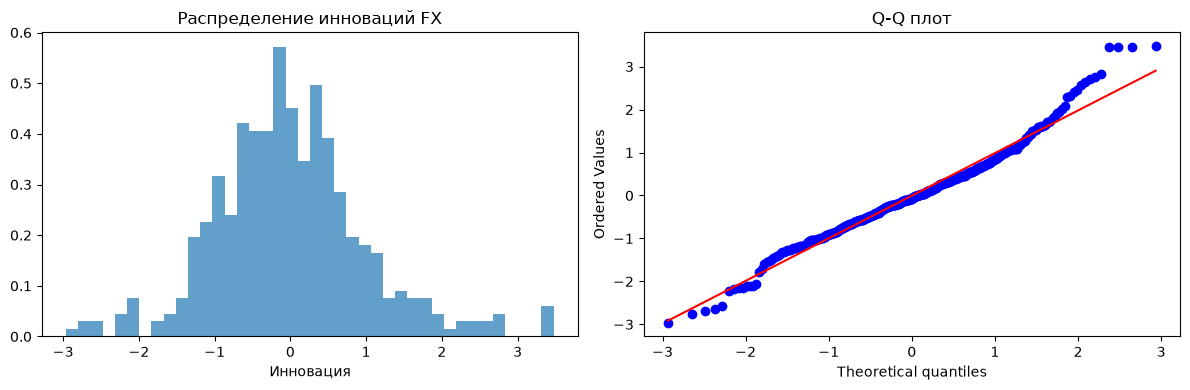

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(
    fx["innovation"],
    bins=40,
    density=True,
    alpha=0.7,
)
axes[0].set_title("Распределение инноваций FX")
axes[0].set_xlabel("Инновация")

stats.probplot(
    fx["innovation"],
    dist="norm",
    plot=axes[1],
)
axes[1].set_title("Q-Q плот")
plt.tight_layout()
plt.show()

# 5. Оцениваем корреляционную матрицу инноваций

Поскольку у рядов могут быть разные календарные интервалы, то при оценке нам надо учитывать только те, где эти календарные интервалы совпадают

In [21]:
def prepare_innovations(df, name):
    data = df.copy()

    data["start_dt"] = data["dt"] - pd.to_timedelta(
        (data["Delta{t}"] * 365).round(),
        unit="D"
    )

    return data[
        ["dt", "start_dt", "innovation"]
    ].rename(columns={"innovation": name})


rub_innov = prepare_innovations(ruonia, "eps_rub")
usd_innov = prepare_innovations(effr, "eps_usd")

fx_innov = fx[
    ["dt", "start_dt", "innovation"]
].rename(columns={"innovation": "eps_fx"})

innovations = (
    rub_innov
    .merge(usd_innov, on=["dt", "start_dt"], how="inner")
    .merge(fx_innov, on=["dt", "start_dt"], how="inner")
    .sort_values("dt")
)

print("Количество общих интервалов:", len(innovations))
innovations.head()

Количество общих интервалов: 359


,dt,start_dt,eps_rub,eps_usd,eps_fx
358,2020-04-07,2020-04-06,-1.066017,-0.269725,-0.882920
357,2020-04-08,2020-04-07,0.146213,-0.269725,-1.051292
356,2020-04-09,2020-04-08,0.941278,-0.269725,-1.257380
355,2020-04-10,2020-04-09,0.505835,-0.269725,-1.035183
354,2020-04-13,2020-04-10,-0.519862,-0.467177,-0.138260


In [25]:
R = innovations.drop(['dt', 'start_dt'], axis=1).corr()

R

,eps_rub,eps_usd,eps_fx
eps_rub,1.000000,-0.003373,-0.025468
eps_usd,-0.003373,1.000000,0.014872
eps_fx,-0.025468,0.014872,1.000000


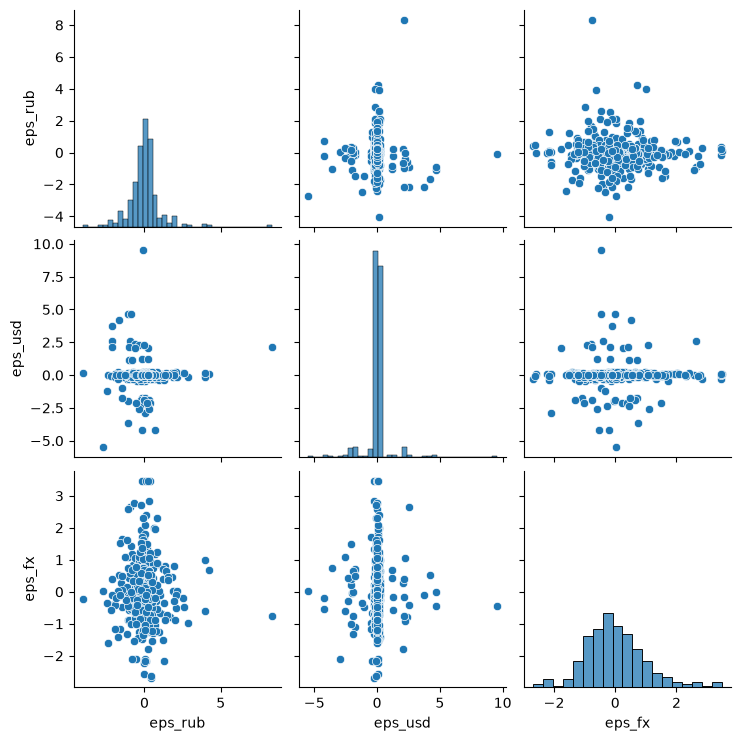

In [38]:
sns.pairplot(innovations.drop(['dt', 'start_dt'], axis=1))